In [23]:
import pandas as pd

df = pd.read_csv('data/34.csv', sep=';')
display(df.head())
print(f"Dataset Shape: {df.shape}")

events_df = pd.read_csv('event_info.csv', sep=';')
events_df['event_start'] = pd.to_datetime(events_df['event_start'])
events_df['event_end'] = pd.to_datetime(events_df['event_end'])
display(events_df.head())
print(f"Events dataset Shape: {df.shape}")

,time_stamp,asset_id,id,train_test,status_type_id,sensor_0_avg,sensor_0_max,sensor_0_min,sensor_0_std,sensor_1_avg,...,wind_speed_60_min,wind_speed_60_std,wind_speed_61_avg,wind_speed_61_max,wind_speed_61_min,wind_speed_61_std,power_62_avg,power_62_max,power_62_min,power_62_std
0,2018-08-25 00:00:00,14,0,train,0,9.0,0.0,0.0,0.0,0.0,...,1.55,2.77,7.84,10.64,1.12,4.14,0.308802,0.393415,0.028452,0.243292
1,2018-08-25 00:10:00,14,1,train,0,10.0,0.0,0.0,0.0,0.0,...,1.58,2.36,7.19,11.54,1.17,4.07,0.257629,0.395761,0.049665,0.161823
2,2018-08-25 00:20:00,14,2,train,0,14.0,0.0,0.0,0.0,0.0,...,1.57,2.53,7.44,10.53,1.12,3.68,0.271053,0.366534,0.037505,0.194789
3,2018-08-25 00:30:00,14,3,train,0,12.0,0.0,0.0,0.0,0.0,...,1.44,2.22,7.23,10.09,1.04,4.07,0.220795,0.321013,0.037239,0.135785
4,2018-08-25 00:40:00,14,4,train,0,12.0,0.0,0.0,0.0,0.0,...,1.42,2.24,6.49,9.27,0.99,3.92,0.183166,0.249208,0.029584,0.118303


Dataset Shape: (56564, 257)


,event_id,event_label,event_start,event_start_id,event_end,event_end_id,event_description
0,34,anomaly,2019-08-25 00:00:00,52531,2019-09-16 00:00:00,55699,high temperature
1,7,anomaly,2026-06-30 00:00:00,52703,2026-07-31 00:00:00,57167,high temperature
2,53,anomaly,2019-12-27 16:40:00,52559,2020-02-07 16:30:00,58606,Rotor Bearing 2 - Damage
3,27,anomaly,2018-09-02 00:00:00,52619,2018-11-02 00:00:00,61403,Turbine is stopped due to a main bearing damage
4,19,anomaly,2025-02-02 00:00:00,52673,2025-02-22 00:00:00,55553,high temperature


Events dataset Shape: (56564, 257)


In [24]:
from sklearn.preprocessing import StandardScaler

features = [
    'wind_speed_61_avg',
    'power_62_avg',         
    'sensor_25_avg',        
    'sensor_19_avg',        
    'sensor_8_avg',         
    'sensor_51_avg',        
    'sensor_52_avg',        
    'sensor_54_avg',       
    'sensor_55_avg'       
]

train_section = df['train_test'] == 'train'
prediction_section = df['train_test'] == 'prediction'

print(len(train_section))
print(len(prediction_section))

X_train_selected = df.loc[train_section, features]
X_prediction_selected = df.loc[prediction_section, features]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_selected)
X_pred_scaled = scaler.transform(X_prediction_selected)

56564
56564


,n_clusters,silhouette_score,inertia,n_iter
0,2,0.432249,290127.414046,6
1,3,0.381148,194754.903080,4
2,4,0.353544,157089.296992,6
3,5,0.358540,127571.016782,14
4,6,0.342584,111994.645145,11
5,7,0.330619,100326.360132,15
6,8,0.302046,91870.085921,18


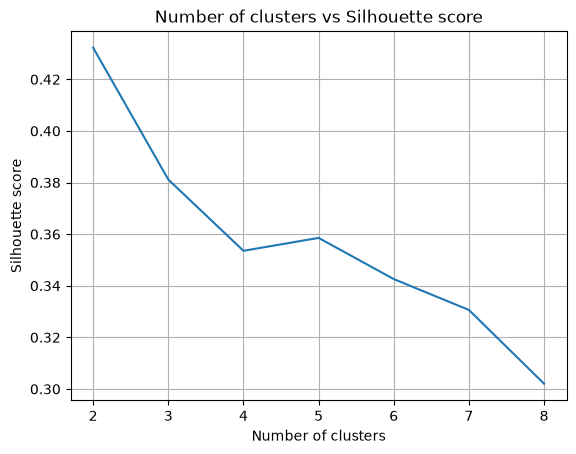

In [25]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn import metrics
import matplotlib.pyplot as plt 

n_clusters_list = [2,3,4,5,6,7,8]

sub_size = min(4000, len(X_train_scaled))
sub_idx = np.random.RandomState(1).choice(len(X_train_scaled), size=sub_size, replace=False)
X_train_sub = X_train_scaled[sub_idx]

scores = []
inertias = []
iterations = []

for n_clusters in n_clusters_list:
    km = KMeans(n_clusters=n_clusters, random_state=1, n_init=10)
    km.fit(X_train_scaled)

    labels_sub = km.predict(X_train_sub)
    score = metrics.silhouette_score(X_train_sub, labels_sub, metric='euclidean')
    scores.append(score)
    inertias.append(km.inertia_)
    iterations.append(km.n_iter_)

km_results = pd.DataFrame({
    'n_clusters': n_clusters_list,
    'silhouette_score': scores,
    'inertia': inertias,
    'n_iter': iterations
})
display(km_results)

plt.plot(n_clusters_list, scores)
plt.title('Number of clusters vs Silhouette score')
plt.xlabel('Number of clusters')
plt.ylabel('Silhouette score')
plt.grid()
plt.show()

It seems like the best number of clusters is 3. Maybe the Silhouette score is not the highest one but when we take into consideration number of iterations we can see that it convergest first. Also from the logical point of view it would be logical to classify turbine states in 3 ways:
- No power - shutdown
- Medium power - low load
- Max power - high load 

In [26]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.neighbors import NearestCentroid

n_clusters = 3
km_optimal = KMeans(n_clusters=n_clusters, random_state=1, n_init=10)
km_optimal.fit(X_train_scaled)

hierarchical = AgglomerativeClustering(n_clusters=n_clusters, linkage='ward')
hier_sub_labels = hierarchical.fit_predict(X_train_sub)

hier_predictor = NearestCentroid().fit(X_train_sub, hier_sub_labels)

pred_km_labels = km_optimal.predict(X_pred_scaled)
pred_hier_labels = hier_predictor.predict(X_pred_scaled)

ari_score = metrics.adjusted_rand_score(pred_km_labels, pred_hier_labels)
print(f"ARI: {ari_score}")

contingency = pd.crosstab(
    pd.Series(pred_km_labels, name='K-Means'),
    pd.Series(pred_hier_labels, name='Hierarchical')
)
display(contingency)

ARI: 0.891606406760227


Hierarchical,0,1,2
K-Means,,,
0,11,0,2
1,107,2026,0
2,1887,0,0
